# 04 — `500 Hz` Waveform Integrity, Filter-Band Spectra & `NeuroKit2` vs Machine Measurements

Because MIMIC-IV-ECG contains `800,035` waveforms (~90 GB), we perform a **stratified `800`-study `500 Hz` waveform audit** spanning:
- Clean `60 Hz notch` studies
- `<not specified>` filter studies
- **`50 Hz notch` misconfigured studies** (testing whether the spectral notch is literally at `50 Hz` vs `60 Hz`!)
- Machine-flagged **`lead reversal`** and **`poor data / artifact`** studies

We also benchmark **`NeuroKit2` `500 Hz` DWT delineation** against MIMIC's own **`machine_measurements.csv`** (`rr_interval`, `QRS`, `PR`, `QT`) on `150` clean studies!

Scanned 800 sampled studies -> readable on disk: 796 | missing .hea/.dat: 4
=== Stratified 500 Hz Waveform Integrity Audit (N = 800) ===


,n_sampled,n_missing,pct_nan,pct_flatline,pct_gt10mv,med_einth_uV
group,,,,,,
50 Hz notch (in US!),160,1,3.14,1.89,0.0,5.04
Clean (60 Hz notch),160,2,0.63,0.00,0.0,5.04
Filtering <not specified>,160,1,0.00,0.00,0.0,18.48
Lead reversal flagged,160,0,3.12,0.00,0.0,5.03
Poor data / artifact,160,0,7.50,0.00,0.0,5.37



=== NeuroKit2 (500 Hz DWT) minus MIMIC Machine Measurements (ms) ===


,n_matched,median_bias_ms,mae_ms
d_RR_ms,149,-3.0,22.3
d_PR_ms,147,-44.0,50.8
d_QRS_ms,145,64.0,65.6
d_QT_ms,145,30.0,59.6


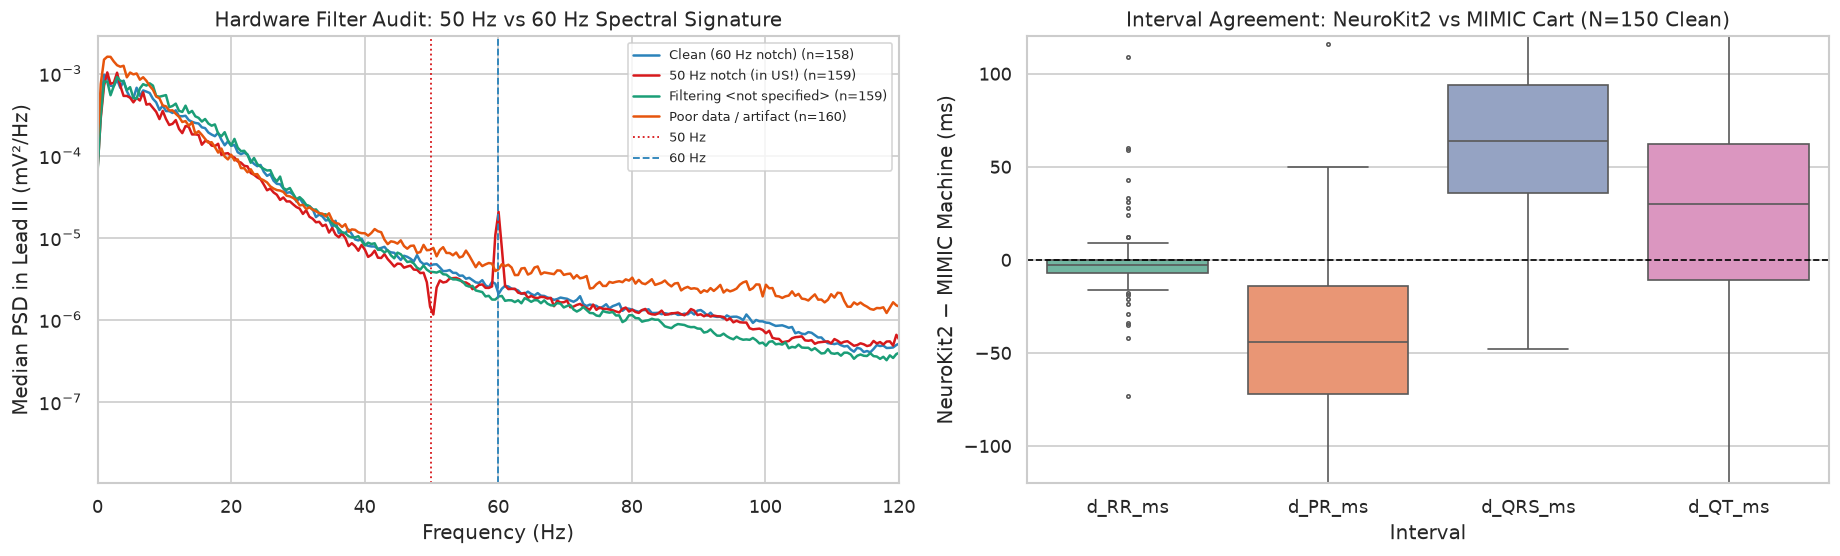

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "mimic_iv_ecg" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate mimic_iv_ecg/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mimic_iv_ecg import MIMICIVECGDataset

MIMIC_DIR = REPO_ROOT / "mimic_iv_ecg"
DATA_DIR = MIMIC_DIR / "data"
QUALITY_DIR = MIMIC_DIR / "quality"
LEADS = MIMICIVECGDataset.LEADS

from concurrent.futures import ThreadPoolExecutor
from scipy import signal as sp_signal
import neurokit2 as nk

rl = pd.read_csv(DATA_DIR / "record_list.csv").set_index("study_id")
mm = pd.read_csv(
    DATA_DIR / "machine_measurements.csv",
    usecols=["study_id", "filtering", "bandwidth", "rr_interval", "p_onset", "qrs_onset", "qrs_end", "t_end"],
).set_index("study_id")
err_df = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz", index_col="study_id")

rng = np.random.default_rng(42)
strata = {
    "Clean (60 Hz notch)":       err_df.index[(err_df["severity_tier"] == "0_clean") & (mm.loc[err_df.index, "filtering"] == "60 Hz notch Baseline filter")],
    "Filtering <not specified>": err_df.index[err_df["err_hw_filtering_unspecified"] == 1],
    "50 Hz notch (in US!)":      err_df.index[err_df["err_hw_50hz_notch_in_us"] == 1],
    "Lead reversal flagged":     err_df.index[err_df["err_rep_lead_reversal"] == 1],
    "Poor data / artifact":      err_df.index[err_df["err_rep_poor_quality_or_artifact"] == 1],
}

scan_items = []
for name, pool in strata.items():
    chosen = rng.choice(pool.to_numpy(), size=min(160, len(pool)), replace=False)
    for sid in chosen:
        scan_items.append((name, int(sid)))

def scan_mimic_wave(item: tuple[str, int]) -> dict:
    grp, sid = item
    rel = rl.loc[sid, "path"]
    hea_p = DATA_DIR / (rel + ".hea")
    if not hea_p.exists():
        return {"group": grp, "study_id": sid, "missing_file": True}
    try:
        sig, _ = wfdb.rdsamp(str(DATA_DIR / rel))
    except Exception:
        return {"group": grp, "study_id": sid, "missing_file": True}
    has_nan = bool(np.isnan(sig).any() or np.isinf(sig).any())
    sig_c = np.nan_to_num(sig)
    min_std = float(sig_c.std(axis=0).min())
    max_abs = float(np.abs(sig_c).max())
    einth = float(np.sqrt(np.mean((sig_c[:, 1] - (sig_c[:, 0] + sig_c[:, 2])) ** 2)))
    f, pxx = sp_signal.welch(sig_c[:, 1], fs=500.0, nperseg=1024)
    return {
        "group": grp, "study_id": sid, "missing_file": False, "has_nan": has_nan,
        "flatline": min_std < 0.005, "extreme_10mv": max_abs > 10.0,
        "einthoven_rmse_mv": einth, "psd": pxx,
    }

with ThreadPoolExecutor(max_workers=16) as pool:
    w_res = list(pool.map(scan_mimic_wave, scan_items))

w_valid = [r for r in w_res if not r["missing_file"]]
print(f"Scanned {len(w_res):,} sampled studies -> readable on disk: {len(w_valid):,} | missing .hea/.dat: {len(w_res) - len(w_valid):,}")
wdf = pd.DataFrame([{k: v for k, v in r.items() if k != "psd"} for r in w_res])
print("=== Stratified 500 Hz Waveform Integrity Audit (N = {:,}) ===".format(len(wdf)))
display(
    wdf.groupby("group").agg(
        n_sampled=("study_id", "count"),
        n_missing=("missing_file", "sum"),
        pct_nan=("has_nan", lambda s: round(s.dropna().mean() * 100, 2) if s.notna().any() else np.nan),
        pct_flatline=("flatline", lambda s: round(s.dropna().mean() * 100, 2) if s.notna().any() else np.nan),
        pct_gt10mv=("extreme_10mv", lambda s: round(s.dropna().mean() * 100, 2) if s.notna().any() else np.nan),
        med_einth_uV=("einthoven_rmse_mv", lambda s: round(s.dropna().median() * 1000, 2) if s.notna().any() else np.nan),
    )
)

# Spectral comparison across hardware filtering settings (50 Hz vs 60 Hz notch!)
f500 = np.linspace(0, 250, len(w_valid[0]["psd"]))
fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))
for grp, col in [("Clean (60 Hz notch)", "#2b83ba"), ("50 Hz notch (in US!)", "#d7191c"), ("Filtering <not specified>", "#1b9e77"), ("Poor data / artifact", "#e6550d")]:
    psds = [r["psd"] for r in w_valid if r["group"] == grp]
    if psds:
        axes[0].semilogy(f500, np.median(np.vstack(psds), axis=0), lw=1.5, color=col, label=f"{grp} (n={len(psds)})")
axes[0].axvline(50, color="#d7191c", ls=":", lw=1.1, label="50 Hz")
axes[0].axvline(60, color="#2b83ba", ls="--", lw=1.1, label="60 Hz")
axes[0].set_xlim(0, 120)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Median PSD in Lead II (mV²/Hz)")
axes[0].set_title("Hardware Filter Audit: 50 Hz vs 60 Hz Spectral Signature")
axes[0].legend(fontsize=7.8)

# Benchmark NeuroKit2 500 Hz vs MIMIC machine_measurements on up to 150 readable clean studies
clean_150 = [r["study_id"] for r in w_valid if r["group"] == "Clean (60 Hz notch)"][:150]
cmp_rows = []
for sid in clean_150:
    sig, _ = wfdb.rdsamp(str(DATA_DIR / rl.loc[sid, "path"]))
    w2 = np.nan_to_num(sig[:, 1])
    try:
        cln = nk.ecg_clean(w2, sampling_rate=500, method="neurokit")
        _, rinfo = nk.ecg_peaks(cln, sampling_rate=500, correct_artifacts=False)
        rp = np.asarray(rinfo.get("ECG_R_Peaks", []), dtype=int)
        if len(rp) < 4:
            continue
        nk_rr = float(np.median(np.diff(rp)) * 2.0)
        _, wv = nk.ecg_delineate(cln, rp, sampling_rate=500, method="dwt")
        def med_ms(k0, k1, lo, hi):
            vals = [(float(b) - float(a)) * 2.0 for a, b in zip(wv.get(k0, []), wv.get(k1, [])) if pd.notna(a) and pd.notna(b) and lo <= (float(b) - float(a)) * 2.0 <= hi]
            return float(np.median(vals)) if vals else np.nan
        row_m = mm.loc[sid].replace(29999, np.nan)
        cmp_rows.append({
            "d_RR_ms": nk_rr - float(row_m["rr_interval"]),
            "d_PR_ms": med_ms("ECG_P_Onsets", "ECG_R_Onsets", 60, 450) - float(row_m["qrs_onset"] - row_m["p_onset"]),
            "d_QRS_ms": med_ms("ECG_R_Onsets", "ECG_R_Offsets", 40, 260) - float(row_m["qrs_end"] - row_m["qrs_onset"]),
            "d_QT_ms": med_ms("ECG_R_Onsets", "ECG_T_Offsets", 200, 700) - float(row_m["t_end"] - row_m["qrs_onset"]),
        })
    except Exception:
        continue

cmp_df = pd.DataFrame(cmp_rows)
print("\n=== NeuroKit2 (500 Hz DWT) minus MIMIC Machine Measurements (ms) ===")
display(pd.DataFrame({
    "n_matched": cmp_df.notna().sum(),
    "median_bias_ms": cmp_df.median(),
    "mae_ms": cmp_df.abs().mean(),
}).round(1))

sns.boxplot(data=cmp_df.melt(var_name="Interval", value_name="Diff_ms").dropna(), x="Interval", y="Diff_ms", ax=axes[1], palette="Set2", fliersize=2)
axes[1].axhline(0, color="black", ls="--", lw=1)
axes[1].set_ylim(-120, 120)
axes[1].set_ylabel("NeuroKit2 − MIMIC Machine (ms)")
axes[1].set_title("Interval Agreement: NeuroKit2 vs MIMIC Cart (N=150 Clean)")

plt.tight_layout()
plt.show()